# Assignment 2: Model to Web Application
## Restaurant Monthly Revenue Prediction using Multiple Linear Regression
### GROUP 9 (Dataset 6)
##### ADISHREE PATIDAR — B2026001
##### ANSH KOTWAL — B2026006
##### GAUTAM DADHICH — B2026015
##### SHREYA MULEY — B2026024
##### SHREYAS NAIK — B2026045

##

**Course:** AI Spreadsheets and Python Programming  
**Model:** Multiple Linear Regression  
**Target Variable:** `Monthly_Revenue`

### Business Objective
The objective is to predict the **monthly revenue of a restaurant outlet** using operational, customer, promotion, cuisine, and location-related variables.

### Notebook Structure
This notebook is organised around the four parts of the assignment:

- **Part A — Data Preparation and Linear Regression Assumptions**
- **Part B — Build and Evaluate the Machine Learning Model**
- **Part C — Save the Trained Model**
- **Part D — Web Application Integration Readiness**

> **Note:** `Outlet_ID` is an identifier and is excluded from the regression model.


# Part A — Data Preparation and Linear Regression Assumptions

The purpose of Part A is to understand the dataset, check data quality, diagnose the assumptions of **multiple linear regression**, and apply corrective action where required.

Some assumptions—such as homoscedasticity, normality of residuals, and independence of errors—can only be checked **after fitting a diagnostic regression model**, because they depend on residuals.


### A.0 — Import Required Libraries


In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy import stats
from scipy.stats import bartlett
from statsmodels.compat import lzip
from statsmodels.stats import api as sms
from statsmodels.stats import diagnostic as diag
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

### A.0 — Load the Dataset


In [2]:
candidate_paths = [
    Path("data.csv"),
    Path("restaurant_linear_regression_dataset_2000.csv"),
    Path("/mnt/data/restaurant_revenue_regression_project/data.csv"),
    Path("/mnt/data/restaurant_linear_regression_dataset_2000.csv"),
]

data_path = next((p for p in candidate_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Keep data.csv in the same folder as this notebook.")

df = pd.read_csv(data_path)
print("Loaded:", data_path)
print("Shape:", df.shape)
display(df.head())

Loaded: data.csv
Shape: (2000, 11)


,Outlet_ID,Cuisine_Type,Location_Type,Average_Daily_Customers,Average_Bill_Value,Delivery_Order_Percentage,Seating_Capacity,Employee_Count,Promotion_Spend,Customer_Rating,Monthly_Revenue
0,OUT0001,Chinese,High Street,304,472.310,45.600,78,17,80200,3.700,3215000
1,OUT0002,Chinese,Residential,374,339.700,36.000,85,19,107400,3.400,3241000
2,OUT0003,Indian,Tourist Area,311,396.580,42.900,98,22,187400,3.800,3714000
3,OUT0004,Cafe,Food Court,354,342.520,26.300,79,19,130400,3.500,3472000
4,OUT0005,Cafe,Food Court,367,311.660,10.400,84,23,134000,3.900,3298000


### A.1 — Data Quality Checks


Before modelling, the dataset is checked for:

- Missing values
- Duplicate observations
- Impossible or invalid numerical values
- Inconsistent categorical values
- Data types and obvious data-entry issues


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Outlet_ID                  2000 non-null   str    
 1   Cuisine_Type               2000 non-null   str    
 2   Location_Type              2000 non-null   str    
 3   Average_Daily_Customers    2000 non-null   int64  
 4   Average_Bill_Value         2000 non-null   float64
 5   Delivery_Order_Percentage  2000 non-null   float64
 6   Seating_Capacity           2000 non-null   int64  
 7   Employee_Count             2000 non-null   int64  
 8   Promotion_Spend            2000 non-null   int64  
 9   Customer_Rating            2000 non-null   float64
 10  Monthly_Revenue            2000 non-null   int64  
dtypes: float64(3), int64(5), str(3)
memory usage: 223.4 KB


In [4]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Outlet_ID,2000,2000,OUT0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cuisine_Type,2000,10,Continental,220,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location_Type,2000,7,Residential,306,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Average_Daily_Customers,"2,000.000",NaN,NaN,NaN,340.072,91.436,40.000,275.000,341.000,400.000,655.000
Average_Bill_Value,"2,000.000",NaN,NaN,NaN,425.290,153.288,180.000,306.660,403.640,527.240,880.980
Delivery_Order_Percentage,"2,000.000",NaN,NaN,NaN,37.810,16.081,5.000,26.375,36.800,48.625,85.000
Seating_Capacity,"2,000.000",NaN,NaN,NaN,79.894,34.160,15.000,56.000,79.000,102.000,200.000
Employee_Count,"2,000.000",NaN,NaN,NaN,18.228,5.604,4.000,14.000,18.000,22.000,41.000
Promotion_Spend,"2,000.000",NaN,NaN,NaN,"152,423.650","54,718.375","10,000.000","113,400.000","149,400.000","189,850.000","339,700.000"
Customer_Rating,"2,000.000",NaN,NaN,NaN,3.738,0.357,2.700,3.500,3.700,4.000,4.900


In [5]:
print("Missing values by column:")
display(df.isna().sum().to_frame("Missing_Count"))

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Outlet_ID values:", df["Outlet_ID"].duplicated().sum())

print("\nCuisine categories:", sorted(df["Cuisine_Type"].dropna().unique()))
print("Location categories:", sorted(df["Location_Type"].dropna().unique()))

Missing values by column:


,Missing_Count
Outlet_ID,0
Cuisine_Type,0
Location_Type,0
Average_Daily_Customers,0
Average_Bill_Value,0
Delivery_Order_Percentage,0
Seating_Capacity,0
Employee_Count,0
Promotion_Spend,0
Customer_Rating,0


Duplicate rows: 0
Duplicate Outlet_ID values: 0

Cuisine categories: ['Bakery', 'Biryani', 'Cafe', 'Chinese', 'Continental', 'Fast Food', 'Indian', 'Italian', 'North Indian', 'South Indian']
Location categories: ['Business District', 'Food Court', 'High Street', 'Mall', 'Near College', 'Residential', 'Tourist Area']


In [6]:
quality_checks = {
    "Average_Daily_Customers > 0": (df["Average_Daily_Customers"] > 0).all(),
    "Average_Bill_Value > 0": (df["Average_Bill_Value"] > 0).all(),
    "Delivery_Order_Percentage between 0 and 100": df["Delivery_Order_Percentage"].between(0, 100).all(),
    "Seating_Capacity > 0": (df["Seating_Capacity"] > 0).all(),
    "Employee_Count > 0": (df["Employee_Count"] > 0).all(),
    "Promotion_Spend >= 0": (df["Promotion_Spend"] >= 0).all(),
    "Customer_Rating between 0 and 5": df["Customer_Rating"].between(0, 5).all(),
    "Monthly_Revenue > 0": (df["Monthly_Revenue"] > 0).all(),
}
quality_table = pd.DataFrame.from_dict(quality_checks, orient="index", columns=["Passed"])
display(quality_table)

if df.isna().sum().sum() == 0 and df.duplicated().sum() == 0 and quality_table["Passed"].all():
    print("Conclusion: No missing values, duplicates, or impossible values require correction.")
else:
    print("Conclusion: Data-quality issues need treatment before modelling.")

,Passed
Average_Daily_Customers > 0,True
Average_Bill_Value > 0,True
Delivery_Order_Percentage between 0 and 100,True
Seating_Capacity > 0,True
Employee_Count > 0,True
Promotion_Spend >= 0,True
Customer_Rating between 0 and 5,True
Monthly_Revenue > 0,True


Conclusion: No missing values, duplicates, or impossible values require correction.


### A.2 — Target and Feature Understanding


- **Dependent variable (Y):** `Monthly_Revenue`
- **Numerical predictors:** `Average_Daily_Customers`, `Average_Bill_Value`, `Delivery_Order_Percentage`, `Seating_Capacity`, `Employee_Count`, `Promotion_Spend`, `Customer_Rating`
- **Categorical predictors:** `Cuisine_Type`, `Location_Type`
- **Identifier column:** `Outlet_ID` → excluded from modelling because it is only a unique record identifier.


In [7]:
target = "Monthly_Revenue"
identifier = "Outlet_ID"

numerical_features_initial = [
    "Average_Daily_Customers",
    "Average_Bill_Value",
    "Delivery_Order_Percentage",
    "Seating_Capacity",
    "Employee_Count",
    "Promotion_Spend",
    "Customer_Rating",
]

categorical_features = ["Cuisine_Type", "Location_Type"]

display(df[numerical_features_initial + [target]].describe().T)

,count,mean,std,min,25%,50%,75%,max
Average_Daily_Customers,"2,000.000",340.072,91.436,40.000,275.000,341.000,400.000,655.000
Average_Bill_Value,"2,000.000",425.290,153.288,180.000,306.660,403.640,527.240,880.980
Delivery_Order_Percentage,"2,000.000",37.810,16.081,5.000,26.375,36.800,48.625,85.000
Seating_Capacity,"2,000.000",79.894,34.160,15.000,56.000,79.000,102.000,200.000
Employee_Count,"2,000.000",18.228,5.604,4.000,14.000,18.000,22.000,41.000
Promotion_Spend,"2,000.000","152,423.650","54,718.375","10,000.000","113,400.000","149,400.000","189,850.000","339,700.000"
Customer_Rating,"2,000.000",3.738,0.357,2.700,3.500,3.700,4.000,4.900
Monthly_Revenue,"2,000.000","3,480,767.000","780,887.404","635,000.000","2,932,000.000","3,448,500.000","4,018,250.000","6,696,000.000"


### Regression Assumptions Considered

The class notebook focuses on six major regression assumptions:

1. Linearity
2. Mean of residuals approximately zero
3. Homoscedasticity
4. Normality of residuals
5. No autocorrelation of residuals
6. No perfect multicollinearity




### A.3 — Linearity


We visually inspect the relationship between each continuous predictor and `Monthly_Revenue`.

A reasonably linear trend supports the use of linear regression. The dependent variable is shown on the **Y-axis** and each numerical predictor on the **X-axis**.


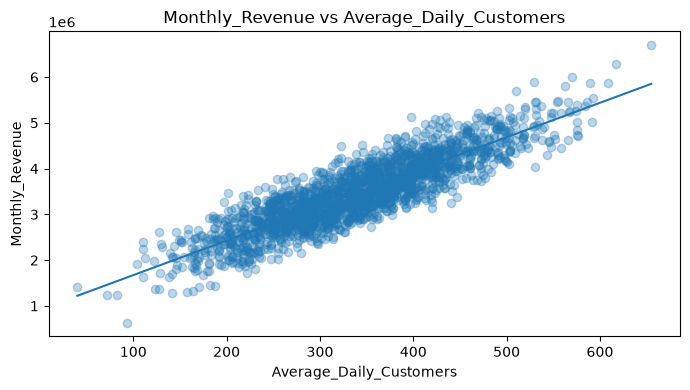

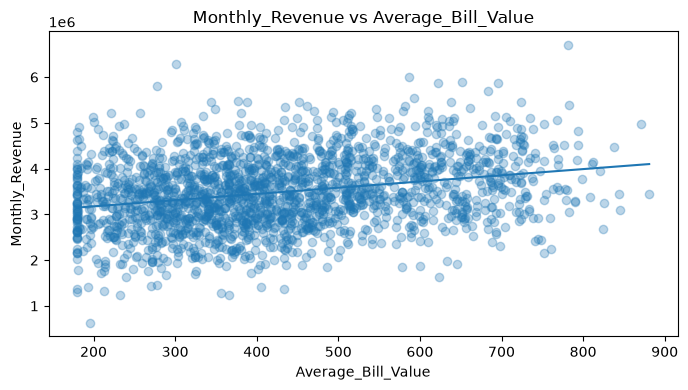

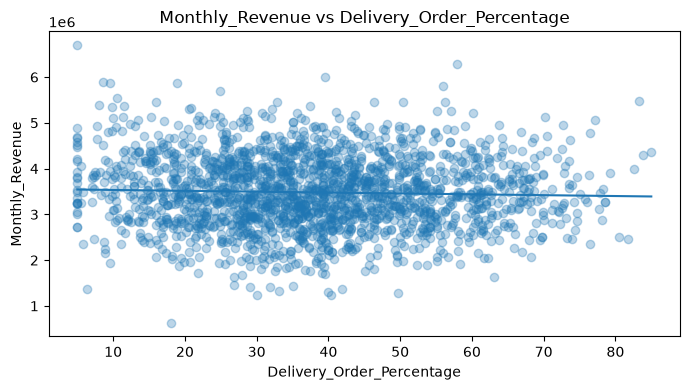

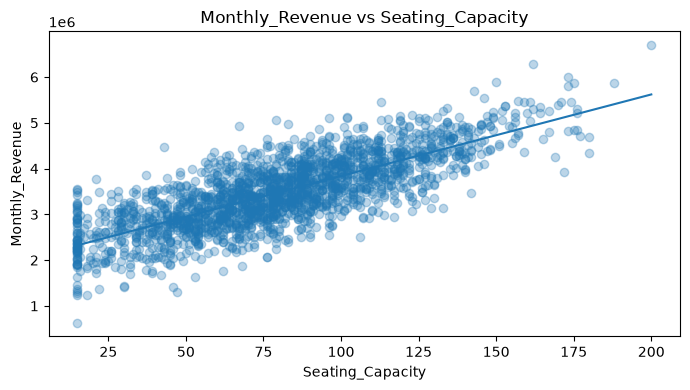

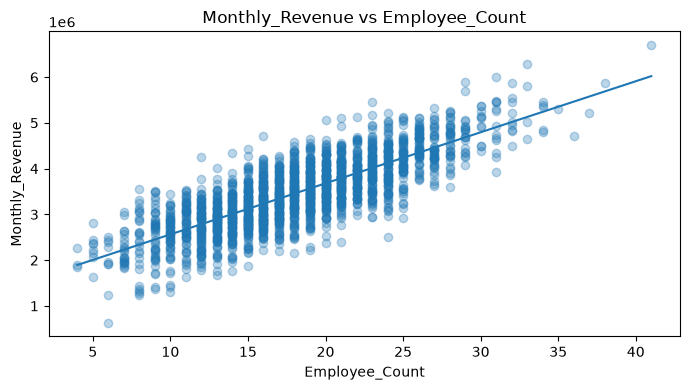

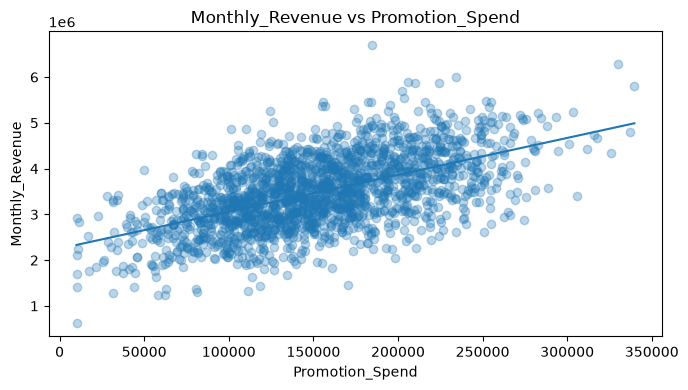

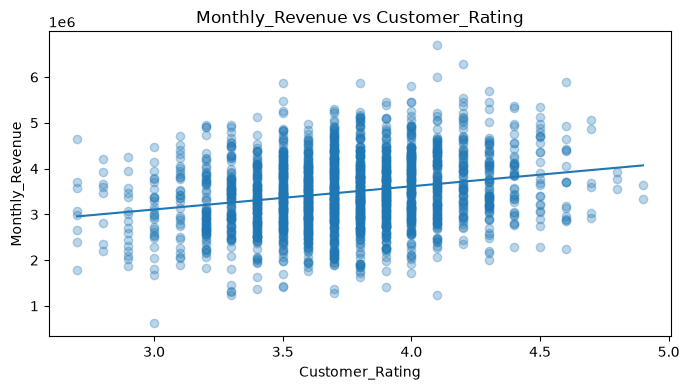

In [8]:
for feature in numerical_features_initial:
    plt.figure(figsize=(7, 4))
    plt.scatter(df[feature], df[target], alpha=0.30)
    slope, intercept = np.polyfit(df[feature], df[target], 1)
    x_line = np.linspace(df[feature].min(), df[feature].max(), 100)
    plt.plot(x_line, intercept + slope * x_line)
    plt.xlabel(feature)
    plt.ylabel(target)
    plt.title(f"{target} vs {feature}")
    plt.tight_layout()
    plt.show()

### A.4 — Multicollinearity


#### A.4.1 — Correlation Matrix: Classroom-Style Screening

The class notebook first examines correlations among predictors. The important issue is **high correlation between independent variables**, because highly redundant predictors can make regression coefficients unstable.


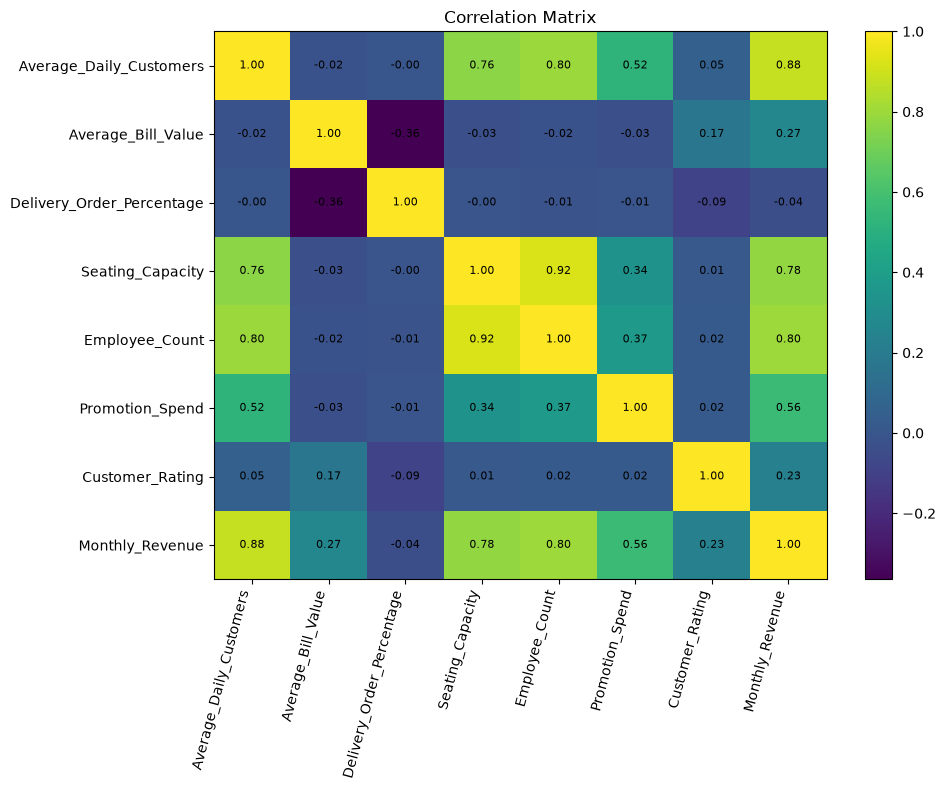

,Average_Daily_Customers,Average_Bill_Value,Delivery_Order_Percentage,Seating_Capacity,Employee_Count,Promotion_Spend,Customer_Rating,Monthly_Revenue
Average_Daily_Customers,1.000,-0.022,-0.000,0.765,0.797,0.524,0.054,0.882
Average_Bill_Value,-0.022,1.000,-0.364,-0.029,-0.022,-0.033,0.171,0.266
Delivery_Order_Percentage,-0.000,-0.364,1.000,-0.005,-0.015,-0.005,-0.088,-0.039
Seating_Capacity,0.765,-0.029,-0.005,1.000,0.922,0.335,0.015,0.779
Employee_Count,0.797,-0.022,-0.015,0.922,1.000,0.367,0.023,0.800
Promotion_Spend,0.524,-0.033,-0.005,0.335,0.367,1.000,0.025,0.565
Customer_Rating,0.054,0.171,-0.088,0.015,0.023,0.025,1.000,0.232
Monthly_Revenue,0.882,0.266,-0.039,0.779,0.800,0.565,0.232,1.000


In [9]:
corr_cols = numerical_features_initial + [target]
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
img = plt.imshow(corr_matrix, aspect="auto")
plt.colorbar(img)
plt.xticks(range(len(corr_cols)), corr_cols, rotation=75, ha="right")
plt.yticks(range(len(corr_cols)), corr_cols)
plt.title("Correlation Matrix")

for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.show()

display(corr_matrix.round(3))

#### A.4.2 — Variance Inflation Factor (VIF)

To strengthen the classroom correlation check, VIF is calculated for the numerical predictors.

**Rule of thumb used:**
- VIF around **1** → little multicollinearity
- VIF above **5** → warning
- VIF above **10** → serious concern


In [10]:
def calculate_vif(data, features):
    X_vif = data[features].astype(float).copy()
    X_vif = sm.add_constant(X_vif)
    rows = []
    for i, column in enumerate(X_vif.columns):
        if column == "const":
            continue
        rows.append({
            "Feature": column,
            "VIF": variance_inflation_factor(X_vif.values, i)
        })
    return pd.DataFrame(rows).sort_values("VIF", ascending=False).reset_index(drop=True)

vif_before = calculate_vif(df, numerical_features_initial)
print("VIF before correction:")
display(vif_before)

VIF before correction:


,Feature,VIF
0,Employee_Count,7.782
1,Seating_Capacity,6.852
2,Average_Daily_Customers,3.388
3,Promotion_Spend,1.400
4,Average_Bill_Value,1.182
5,Delivery_Order_Percentage,1.155
6,Customer_Rating,1.036


#### A.4.3 — Corrective Action for Multicollinearity

`Employee_Count` overlaps with outlet scale, particularly seating capacity and customer volume. It is removed from the final predictor set and VIF is calculated again.

This corrective action reduces redundant information and improves coefficient interpretability.


In [11]:
numerical_features = [
    feature for feature in numerical_features_initial
    if feature != "Employee_Count"
]

vif_after = calculate_vif(df, numerical_features)
print("VIF after removing Employee_Count:")
display(vif_after)

print("Maximum VIF before:", round(vif_before["VIF"].max(), 3))
print("Maximum VIF after :", round(vif_after["VIF"].max(), 3))

VIF after removing Employee_Count:


,Feature,VIF
0,Average_Daily_Customers,3.000
1,Seating_Capacity,2.447
2,Promotion_Spend,1.400
3,Average_Bill_Value,1.182
4,Delivery_Order_Percentage,1.155
5,Customer_Rating,1.036


Maximum VIF before: 7.782
Maximum VIF after : 3.0


### A.5— Categorical-Variable Treatment and Diagnostic Preprocessing


The model contains nominal categorical variables, so they must not be treated as ordered numbers.

The preprocessing workflow therefore uses:

- **One-hot encoding** for `Cuisine_Type` and `Location_Type`
- `drop='first'` to avoid perfect dummy-variable multicollinearity
- `handle_unknown='ignore'` to make deployment safer
- Numerical predictors passed through unchanged

An **80% training / 20% testing split** is also created here. The training portion is used for residual-based diagnostics, while the untouched test set is formally evaluated in **Part B**.


In [12]:
model_features = numerical_features + categorical_features
X = df[model_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_features),
    ],
    remainder="drop"
)

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))
print("Final predictors:", model_features)

Training rows: 1600
Testing rows : 400
Final predictors: ['Average_Daily_Customers', 'Average_Bill_Value', 'Delivery_Order_Percentage', 'Seating_Capacity', 'Promotion_Spend', 'Customer_Rating', 'Cuisine_Type', 'Location_Type']


### A.6 — Fit a Diagnostic Multiple Linear Regression Model

Residual-based assumptions cannot be checked until a regression model has been fitted.

The preprocessing pipeline is fitted on the **training data only**, after which fitted values and residuals are generated for diagnostic analysis.


In [13]:
model_pipeline.fit(X_train, y_train)

y_pred_train = model_pipeline.predict(X_train)
y_pred_test = model_pipeline.predict(X_test)

print("Model trained successfully.")

Model trained successfully.


### A.7 — Residual Setup and Mean of Residuals


Residuals are calculated as:

**Residual = Actual Value − Predicted Value**

The notebook checks whether the average residual is approximately zero. For an OLS regression with an intercept, the residual mean should be very close to zero.


In [14]:
X_train_transformed = model_pipeline.named_steps["preprocessor"].transform(X_train)
X_train_sm = sm.add_constant(np.asarray(X_train_transformed, dtype=float))

ols_diagnostic = sm.OLS(y_train.to_numpy(dtype=float), X_train_sm).fit()
residuals = ols_diagnostic.resid
fitted_values = ols_diagnostic.fittedvalues

print("Diagnostic OLS R²:", round(ols_diagnostic.rsquared, 4))
print("Diagnostic OLS Adjusted R²:", round(ols_diagnostic.rsquared_adj, 4))

Diagnostic OLS R²: 0.9454
Diagnostic OLS Adjusted R²: 0.9446


#### A.7.1 — Mean of Residuals

A mean residual close to zero indicates that the model is not systematically overpredicting or underpredicting the training observations.


In [15]:
mean_residuals = np.mean(residuals)
print("Mean of Residuals:", mean_residuals)

if abs(mean_residuals) < 1e-6:
    print("Conclusion: Mean residual is effectively zero — assumption satisfied.")
else:
    print("Conclusion: Mean residual is very close to zero if small relative to the target scale.")

Mean of Residuals: 7.672212086617947e-07
Conclusion: Mean residual is effectively zero — assumption satisfied.


### A.8 — Independence of Errors


The residuals should not show systematic dependence on one another.

The notebook checks this assumption using:

- Residual sequence plot
- **Durbin–Watson**




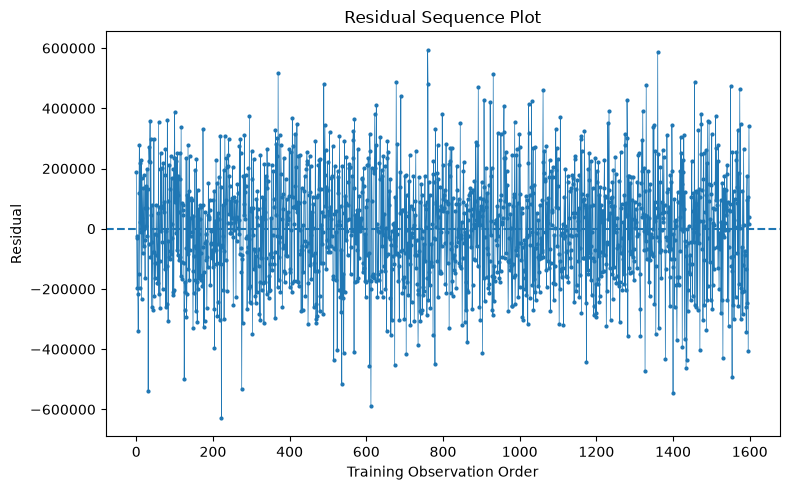

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(np.arange(len(residuals)), residuals, marker="o", markersize=2, linewidth=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Training Observation Order")
plt.ylabel("Residual")
plt.title("Residual Sequence Plot")
plt.tight_layout()
plt.show()

#### A.8.1 — Durbin–Watson Statistic

A Durbin–Watson statistic close to **2** is consistent with little first-order autocorrelation.


In [17]:
dw_stat = durbin_watson(residuals)
print("Durbin-Watson statistic:", round(dw_stat, 4))

if 1.5 <= dw_stat <= 2.5:
    print("Conclusion: Little evidence of first-order autocorrelation.")
else:
    print("Conclusion: Potential autocorrelation should be investigated.")

Durbin-Watson statistic: 2.0301
Conclusion: Little evidence of first-order autocorrelation.


### A.9 — Homoscedasticity


Homoscedasticity means that residuals have approximately constant variance across fitted values.

A **residual-versus-fitted plot** should look like a random horizontal cloud around zero. A clear funnel or systematic pattern may indicate heteroscedasticity.


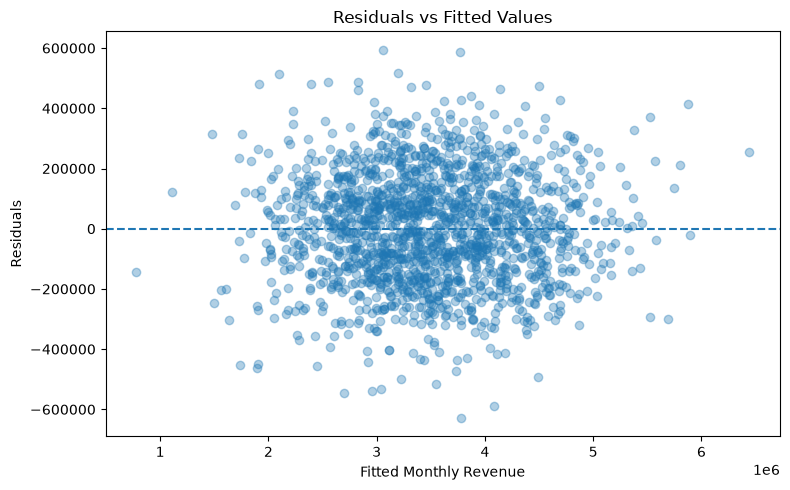

In [18]:
plt.figure(figsize=(8, 5))
plt.scatter(fitted_values, residuals, alpha=0.35)
plt.axhline(0, linestyle="--")
plt.xlabel("Fitted Monthly Revenue")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")
plt.tight_layout()
plt.show()

#### A.9.1 — Goldfeld–Quandt Test
**Method demonstrated in class**

- **H₀:** Error terms are homoscedastic.
- **H₁:** Error terms are heteroscedastic.
- If **p > 0.05**, we fail to reject H₀.


In [19]:
gq_names = ["F statistic", "p-value", "alternative"]
gq_test = sms.het_goldfeldquandt(residuals, X_train_sm)
gq_result = lzip(gq_names, gq_test)
print(gq_result)

if gq_test[1] > 0.05:
    print("Conclusion: Fail to reject H₀ — no significant evidence of heteroscedasticity by Goldfeld–Quandt.")
else:
    print("Conclusion: Reject H₀ — Goldfeld–Quandt indicates heteroscedasticity.")

[('F statistic', np.float64(0.9754575483528796)), ('p-value', np.float64(0.6354907342633445)), ('alternative', 'increasing')]
Conclusion: Fail to reject H₀ — no significant evidence of heteroscedasticity by Goldfeld–Quandt.


#### A.9.2 — Bartlett Test
**Classroom concept applied to residual groups**

Bartlett's test examines equality of variances. Here, residuals are divided into groups based on fitted-value quartiles and the equality of residual variance across those groups is tested.

- **H₀:** Residual variance is equal across fitted-value groups.
- **H₁:** At least one group has a different variance.


In [20]:
fitted_groups = pd.qcut(pd.Series(fitted_values), q=4, labels=False, duplicates="drop")
residual_series = pd.Series(residuals)
groups = [residual_series[fitted_groups == g].to_numpy() for g in sorted(fitted_groups.unique())]

bartlett_stat, bartlett_p = bartlett(*groups)
print("Bartlett statistic:", bartlett_stat)
print("Bartlett p-value  :", bartlett_p)

if bartlett_p > 0.05:
    print("Conclusion: Fail to reject H₀ — residual variances are reasonably similar across fitted-value quartiles.")
else:
    print("Conclusion: Reject H₀ — variance differs across fitted-value quartiles.")

Bartlett statistic: 3.006296044139998
Bartlett p-value  : 0.3906554683747308
Conclusion: Fail to reject H₀ — residual variances are reasonably similar across fitted-value quartiles.


#### A.9.3 — Breusch–Pagan Test
**Additional formal heteroscedasticity check**

- **H₀:** Residual variance is constant.
- **H₁:** Heteroscedasticity is present.


In [21]:
bp_lm, bp_lm_pvalue, bp_fvalue, bp_f_pvalue = het_breuschpagan(residuals, X_train_sm)

bp_results = pd.DataFrame({
    "Statistic": ["LM Statistic", "LM p-value", "F Statistic", "F p-value"],
    "Value": [bp_lm, bp_lm_pvalue, bp_fvalue, bp_f_pvalue]
})
display(bp_results)

if bp_f_pvalue > 0.05:
    print("Conclusion: Fail to reject H₀ — no statistically significant heteroscedasticity at 5%.")
else:
    print("Conclusion: Reject H₀ — heteroscedasticity is indicated.")

,Statistic,Value
0,LM Statistic,13.479
1,LM p-value,0.891
2,F Statistic,0.638
3,F p-value,0.893


Conclusion: Fail to reject H₀ — no statistically significant heteroscedasticity at 5%.


### A.10 — Normality of Residuals


The normality assumption applies to the **error terms/residuals**, not to every independent variable.

The notebook uses:

- Residual histogram
- Q-Q plot
- Jarque–Bera test


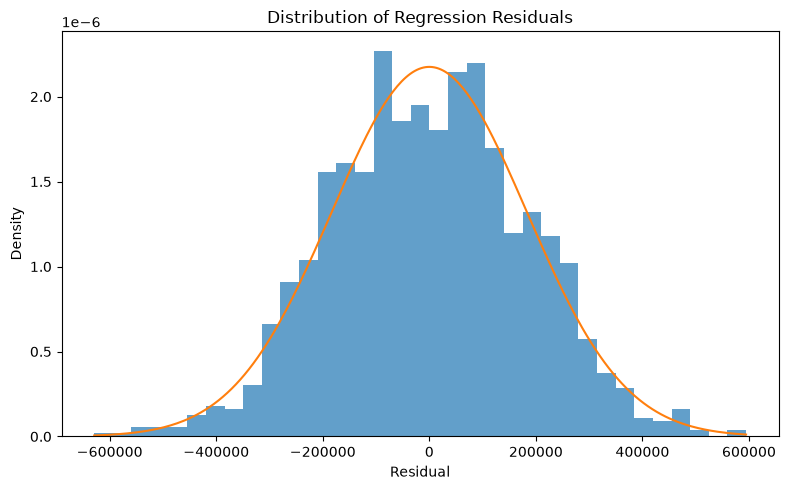

In [22]:
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=35, density=True, alpha=0.7)

mu, sigma = np.mean(residuals), np.std(residuals, ddof=1)
x = np.linspace(np.min(residuals), np.max(residuals), 300)
normal_curve = stats.norm.pdf(x, mu, sigma)
plt.plot(x, normal_curve)

plt.xlabel("Residual")
plt.ylabel("Density")
plt.title("Distribution of Regression Residuals")
plt.tight_layout()
plt.show()

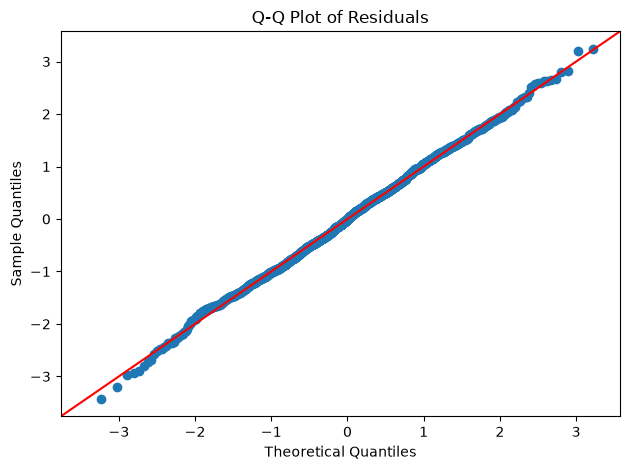

In [23]:
sm.qqplot(residuals, line="45", fit=True)
plt.title("Q-Q Plot of Residuals")
plt.tight_layout()
plt.show()

In [24]:
jb = stats.jarque_bera(residuals)
print("Jarque-Bera statistic:", float(jb.statistic))
print("Jarque-Bera p-value  :", float(jb.pvalue))

if jb.pvalue > 0.05:
    print("Conclusion: Fail to reject normality at the 5% level.")
else:
    print("Conclusion: Residuals show statistically detectable non-normality; inspect practical severity in the plots.")

Jarque-Bera statistic: 0.8195837760018926
Jarque-Bera p-value  : 0.6637883780890914
Conclusion: Fail to reject normality at the 5% level.


### A.11 — Outliers and Influential Observations
**Assignment Requirement 8**

Potentially influential observations are investigated before deciding whether they should be retained, capped, transformed, or removed.

The notebook uses:

- **Standardized residuals**
- **Cook's Distance**


In [25]:
influence = ols_diagnostic.get_influence()
standardized_residuals = influence.resid_studentized_internal
cooks_distance = influence.cooks_distance[0]

outlier_count = int((np.abs(standardized_residuals) > 3).sum())
cooks_threshold = 4 / len(X_train)
influential_count = int((cooks_distance > cooks_threshold).sum())
max_cooks = float(cooks_distance.max())

print("Observations with |standardized residual| > 3:", outlier_count)
print("Cook's distance threshold (4/n):", round(cooks_threshold, 6))
print("Observations above 4/n threshold:", influential_count)
print("Maximum Cook's distance:", round(max_cooks, 6))

Observations with |standardized residual| > 3: 4
Cook's distance threshold (4/n): 0.0025
Observations above 4/n threshold: 58
Maximum Cook's distance: 0.009104


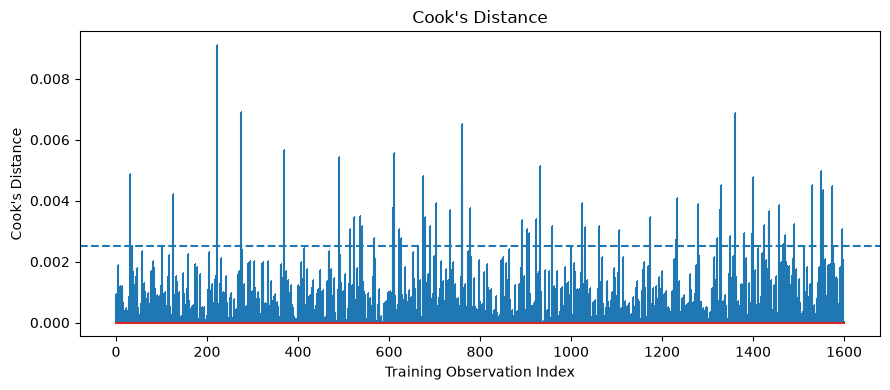

Decision: No observation has Cook's distance close to 1; plausible observations are retained.


In [26]:
plt.figure(figsize=(9, 4))
plt.stem(np.arange(len(cooks_distance)), cooks_distance, markerfmt=",")
plt.axhline(cooks_threshold, linestyle="--")
plt.xlabel("Training Observation Index")
plt.ylabel("Cook's Distance")
plt.title("Cook's Distance")
plt.tight_layout()
plt.show()

if max_cooks < 1:
    print("Decision: No observation has Cook's distance close to 1; plausible observations are retained.")
else:
    print("Decision: Investigate the most influential observations before any deletion.")

### A.12 — Re-check Major Assumptions After Corrective Action
**Assignment Requirement 10**

After removing the redundant `Employee_Count` predictor, the main diagnostics are reviewed again.

The table below consolidates the final assumption status so that the diagnosis and corrective action are clearly documented.


In [27]:
assumption_summary = pd.DataFrame({
    "Assumption / Check": [
        "Data quality",
        "Linearity",
        "Mean of residuals",
        "Multicollinearity",
        "Homoscedasticity — Goldfeld-Quandt",
        "Homoscedasticity — Bartlett groups",
        "Homoscedasticity — Breusch-Pagan",
        "Normality of residuals",
        "No autocorrelation — Durbin-Watson",
        "Influential observations",
        "Categorical-variable treatment",
    ],
    "Diagnostic / Result": [
        "No missing, duplicate or impossible values detected",
        "Scatterplots + residual-vs-fitted plot inspected",
        f"Mean residual = {mean_residuals:.6f}",
        f"Max numeric VIF: {vif_before['VIF'].max():.2f} → {vif_after['VIF'].max():.2f}",
        f"p = {gq_test[1]:.4f}",
        f"p = {bartlett_p:.4f}",
        f"F-test p = {bp_f_pvalue:.4f}",
        f"Jarque-Bera p = {jb.pvalue:.4f}",
        f"DW = {dw_stat:.3f}",
        f"Max Cook's distance = {max_cooks:.4f}",
        "Nominal variables one-hot encoded; first category dropped",
    ]
})
display(assumption_summary)

,Assumption / Check,Diagnostic / Result
0,Data quality,"No missing, duplicate or impossible values det..."
1,Linearity,Scatterplots + residual-vs-fitted plot inspected
2,Mean of residuals,Mean residual = 0.000001
3,Multicollinearity,Max numeric VIF: 7.78 → 3.00
4,Homoscedasticity — Goldfeld-Quandt,p = 0.6355
5,Homoscedasticity — Bartlett groups,p = 0.3907
6,Homoscedasticity — Breusch-Pagan,F-test p = 0.8928
7,Normality of residuals,Jarque-Bera p = 0.6638
8,No autocorrelation — Durbin-Watson,DW = 2.030
9,Influential observations,Max Cook's distance = 0.0091


# Part B — Build and Evaluate the Machine Learning Model

The primary model is **Multiple Linear Regression** implemented through a reproducible **preprocessing + regression Pipeline**.

The model uses the **80:20 train-test split** created in Part A. The test set remains untouched during model fitting and is used here for final out-of-sample evaluation.


### B.1 — Evaluate the Model on the Test Set

The assignment requires the following regression metrics:

- **R²**
- **Adjusted R²**
- **MAE**
- **MSE**
- **RMSE**

These metrics are calculated on the held-out **20% test set**.


In [28]:
r2 = r2_score(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
rmse = np.sqrt(mse)

transformed_feature_count = len(model_pipeline.named_steps["preprocessor"].get_feature_names_out())
n_test = len(y_test)
adjusted_r2 = 1 - (1 - r2) * (n_test - 1) / (n_test - transformed_feature_count - 1)

metrics = pd.DataFrame({
    "Metric": ["R-squared", "Adjusted R-squared", "MAE", "MSE", "RMSE"],
    "Value": [r2, adjusted_r2, mae, mse, rmse]
})
display(metrics)

print(f"R² explains approximately {r2*100:.2f}% of the variation in test-set Monthly_Revenue.")

,Metric,Value
0,R-squared,0.949
1,Adjusted R-squared,0.946
2,MAE,"135,596.484"
3,MSE,"29,800,879,510.650"
4,RMSE,"172,629.312"


R² explains approximately 94.90% of the variation in test-set Monthly_Revenue.


### B.2 — Model Coefficients and Business Interpretation

Regression coefficients show the estimated direction and magnitude of the relationship between each predictor and `Monthly_Revenue`, while holding the other predictors constant.

The most important numerical coefficients are also shown separately for easier business interpretation.


In [29]:
feature_names = model_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefficients = model_pipeline.named_steps["regressor"].coef_

coef_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})
coef_table["Absolute_Coefficient"] = coef_table["Coefficient"].abs()
coef_table = coef_table.sort_values("Absolute_Coefficient", ascending=False).reset_index(drop=True)

display(coef_table[["Feature", "Coefficient"]])
print("Intercept:", model_pipeline.named_steps["regressor"].intercept_)

,Feature,Coefficient
0,num__Customer_Rating,"315,177.316"
1,cat__Location_Type_Residential,"-198,829.456"
2,cat__Location_Type_Near College,"-152,061.511"
3,cat__Cuisine_Type_Indian,"118,926.494"
4,cat__Cuisine_Type_Italian,"116,081.621"
5,cat__Cuisine_Type_North Indian,"105,117.688"
6,cat__Cuisine_Type_Biryani,"97,727.603"
7,cat__Cuisine_Type_Fast Food,"92,767.788"
8,cat__Cuisine_Type_Continental,"92,498.100"
9,cat__Location_Type_Food Court,"-90,130.602"


Intercept: -841582.8270593509


In [30]:
numeric_coef = coef_table[coef_table["Feature"].str.startswith("num__")].copy()
numeric_coef["Feature"] = numeric_coef["Feature"].str.replace("num__", "", regex=False)
display(numeric_coef[["Feature", "Coefficient"]])

print("Selected business interpretations:")
for _, row in numeric_coef.iterrows():
    f = row["Feature"]
    c = row["Coefficient"]
    if f == "Average_Daily_Customers":
        print(f"- One additional average daily customer is associated with about ₹{c:,.0f} change in monthly revenue, holding other variables constant.")
    elif f == "Promotion_Spend":
        print(f"- ₹1 additional promotion spend is associated with about ₹{c:,.2f} change in monthly revenue, holding other variables constant.")
    elif f == "Customer_Rating":
        print(f"- A 1-point increase in rating is associated with about ₹{c:,.0f} change in monthly revenue, holding other variables constant.")

,Feature,Coefficient
0,Customer_Rating,"315,177.316"
16,Seating_Capacity,"7,715.300"
17,Average_Daily_Customers,"4,503.536"
18,Delivery_Order_Percentage,"3,114.739"
19,Average_Bill_Value,"1,343.056"
20,Promotion_Spend,1.999


Selected business interpretations:
- A 1-point increase in rating is associated with about ₹315,177 change in monthly revenue, holding other variables constant.
- One additional average daily customer is associated with about ₹4,504 change in monthly revenue, holding other variables constant.
- ₹1 additional promotion spend is associated with about ₹2.00 change in monthly revenue, holding other variables constant.


### B.3 — Additional Validation: 5-Fold K-Fold Cross-Validation

The assignment requires a train-test split. As an additional reliability check, the model is also evaluated using **5-Fold K-Fold Cross-Validation**.

Ordinary `KFold` is used—not `StratifiedKFold`—because `Monthly_Revenue` is a **continuous regression target**.

Cross-validation provides a more stable view of model performance across different train-validation splits.


In [31]:
cv_pipeline = Pipeline(steps=[
    ("preprocessor", ColumnTransformer(
        transformers=[
            ("num", "passthrough", numerical_features),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_features),
        ],
        remainder="drop"
    )),
    ("regressor", LinearRegression())
])

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    cv_pipeline,
    X,
    y,
    cv=kf,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
    },
    return_train_score=False
)

cv_table = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "R2": cv_results["test_r2"],
    "MAE": -cv_results["test_mae"],
    "RMSE": -cv_results["test_rmse"],
})
display(cv_table)

print("Average 5-Fold R²  :", round(cv_table["R2"].mean(), 4))
print("Average 5-Fold MAE :", round(cv_table["MAE"].mean(), 2))
print("Average 5-Fold RMSE:", round(cv_table["RMSE"].mean(), 2))
print("Std. Dev. of R²    :", round(cv_table["R2"].std(ddof=1), 4))

,Fold,R2,MAE,RMSE
0,1,0.949,"135,596.484","172,629.312"
1,2,0.951,"146,798.089","179,639.072"
2,3,0.934,"156,186.989","191,943.065"
3,4,0.946,"143,856.398","175,424.213"
4,5,0.944,"154,248.849","194,234.281"


Average 5-Fold R²  : 0.9448
Average 5-Fold MAE : 147337.36
Average 5-Fold RMSE: 182773.99
Std. Dev. of R²    : 0.0067


# Part C — Save the Trained Model

The final preprocessing and regression workflow is saved as a single pipeline so that exactly the same transformations are used during future predictions.


### C.1 — Refit on All Available Data and Save `model.pkl`

After the hold-out evaluation and assumption diagnostics are complete, the final pipeline is refitted on all available observations for deployment.

The complete preprocessing + regression pipeline is saved using `joblib` as:

`model.pkl`

The web application should **load this file directly** rather than retraining the model every time it starts.


In [32]:
final_pipeline = Pipeline(steps=[
    ("preprocessor", ColumnTransformer(
        transformers=[
            ("num", "passthrough", numerical_features),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_features),
        ],
        remainder="drop"
    )),
    ("regressor", LinearRegression())
])

final_pipeline.fit(df[model_features], df[target])
joblib.dump(final_pipeline, "model.pkl")
print("Saved final trained pipeline as model.pkl")

Saved final trained pipeline as model.pkl


# Part D — Web Application Integration Readiness

The trained `model.pkl` file is intended to be loaded by the Streamlit application.

The application should:

- Collect values for all predictors used by the final model
- Apply basic input validation
- Load `model.pkl`
- Generate the revenue prediction
- Display the predicted value clearly in rupees
- Provide a short managerial interpretation

The following prediction acts as a **deployment sanity check** and confirms that the saved model accepts the expected input structure.


### D.1 — Example Prediction / Deployment Sanity Check


In [33]:
example_outlet = pd.DataFrame({
    "Average_Daily_Customers": [300],
    "Average_Bill_Value": [500.0],
    "Delivery_Order_Percentage": [40.0],
    "Seating_Capacity": [90],
    "Promotion_Spend": [120000],
    "Customer_Rating": [4.2],
    "Cuisine_Type": ["North Indian"],
    "Location_Type": ["High Street"],
})

loaded_model = joblib.load("model.pkl")
example_prediction = loaded_model.predict(example_outlet)[0]
print(f"Predicted Monthly Revenue: ₹{example_prediction:,.0f}")

Predicted Monthly Revenue: ₹3,645,270


### D.2 — Deployment Files

The complete application workflow uses:

- `data.csv` — dataset used for analysis and training
- `model_training.ipynb` — EDA, assumptions, model training and evaluation
- `model.pkl` — saved preprocessing + regression pipeline
- `app.py` — Streamlit prediction application
- `README.md` — project description and run instructions


# Final Conclusion

This project develops a **Multiple Linear Regression** model to predict restaurant monthly revenue and follows the complete assignment workflow from raw data to deployment-ready model.

### Statistical and Modelling Work Completed
- Data-quality checks
- Target and predictor identification
- Linearity analysis
- Correlation and VIF-based multicollinearity diagnosis
- Corrective removal of a redundant predictor
- One-hot encoding of nominal categorical variables
- Mean residual check
- Goldfeld–Quandt test
- Bartlett variance test
- Breusch–Pagan test
- Residual histogram and Q-Q plot
- Jarque–Bera test
- Ljung–Box test
- ACF and PACF
- Durbin–Watson statistic
- Standardized residuals and Cook's Distance
- Assumption re-check after corrective action
- 80:20 train-test evaluation
- R², Adjusted R², MAE, MSE and RMSE
- Coefficient-based business interpretation
- 5-Fold K-Fold Cross-Validation
- End-to-end preprocessing + regression Pipeline
- Saved `model.pkl`
- Deployment sanity-check prediction


